<a href="https://colab.research.google.com/github/skrobert03/git_practice/blob/main/StoryMap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import folium

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded.")


Libraries loaded.


In [11]:
# Load in the 2025 Tennessee tracts
tracts = gpd.read_file('/content/tl_2025_47_tract.shp')
tracts.head()


,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,47,037,011400,47037011400,1400000US47037011400,114,Census Tract 114,G5020,S,2651411,0,+36.1985212,-086.7337810,"POLYGON ((-86.74899 36.19845, -86.74874 36.198..."
1,47,179,060700,47179060700,1400000US47179060700,607,Census Tract 607,G5020,S,906225,0,+36.3016077,-082.3712145,"POLYGON ((-82.38065 36.29734, -82.3806 36.2974..."
2,47,179,060800,47179060800,1400000US47179060800,608,Census Tract 608,G5020,S,2315123,0,+36.3085185,-082.3517735,"POLYGON ((-82.36534 36.30874, -82.36523 36.308..."
3,47,065,011446,47065011446,1400000US47065011446,114.46,Census Tract 114.46,G5020,S,6015761,0,+35.0188093,-085.1689684,"POLYGON ((-85.18929 35.0111, -85.18831 35.0113..."
4,47,179,061000,47179061000,1400000US47179061000,610,Census Tract 610,G5020,S,2040923,0,+36.3347551,-082.3417905,"POLYGON ((-82.3544 36.3266, -82.3542 36.32679,..."


<Axes: >

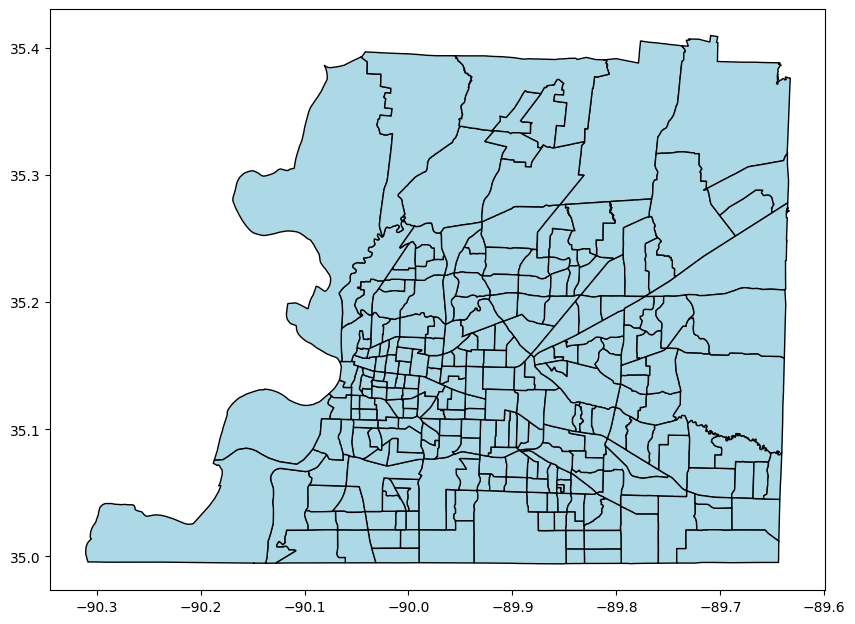

In [12]:
shelby_tracts = tracts[tracts['COUNTYFP'] == '157']
shelby_tracts.shape
shelby_tracts.plot(figsize=(10,10), color='lightblue', edgecolor='black')


In [7]:
parks = gpd.read_file('/content/City_of_Memphis_Parks.geojson')
parks.head()



,OBJECTID,ParkID,GISTrkrID,SourceID,Park_Name,Park_Designation,Park_Owner_Type,Park_Local_Owner,Park_Manager_Type,Park_Local_Manager,...,Park_State_FIPS,Park_County,Park_County_FIPS,Park_Place,Park_Place_FIPS,Park_UrbanArea,Park_UrbanArea_ID,Park_Zip,ORIG_FID,geometry
0,1,4748000-0001,143.0,9.0,Oakley Park,LP,MUNI,MEMPHIS PARKS,MUNI,MEMPHIS PARKS,...,47,Shelby County,47157,Memphis city,4748000,"Memphis, TN--MS--AR",56116,38128,11162,POINT (-89.9464 35.25732)
1,2,4748000-0003,143.0,15.0,Egypt Central Park,LP,CNTY,SHELBY COUNTY DEPARTMENT OF PUBLIC WORKS (SHEL...,CNTY,SHELBY COUNTY DEPARTMENT OF PUBLIC WORKS (SHEL...,...,47,Shelby County,47157,Memphis city,4748000,"Memphis, TN--MS--AR",56116,38128,11163,POINT (-89.9296 35.24219)
2,3,4748000-0004,143.0,18.0,Pickett Park,LP,MUNI,MEMPHIS PARKS,MUNI,MEMPHIS PARKS,...,47,Shelby County,47157,Memphis city,4748000,"Memphis, TN--MS--AR",56116,38127,11164,POINT (-89.9784 35.23137)
3,4,4748000-0005,143.0,20.0,Willingham Park,LP,MUNI,MEMPHIS PARKS,MUNI,MEMPHIS PARKS,...,47,Shelby County,47157,Memphis city,4748000,"Memphis, TN--MS--AR",56116,38128,11165,POINT (-89.95241 35.22812)
4,5,4748000-0006,143.0,22.0,Pershing Park,LP,MUNI,MEMPHIS PARKS,MUNI,MEMPHIS PARKS,...,47,Shelby County,47157,Memphis city,4748000,"Memphis, TN--MS--AR",56116,38127,11166,POINT (-90.01131 35.22757)


In [9]:
parks = parks.to_crs(shelby_tracts.crs)
joined = gpd.sjoin(parks, shelby_tracts, predicate='within')
counts = joined.groupby('GEOID').size().reset_index(name='park_count')

shelby_tracts = shelby_tracts.merge(counts, on='GEOID', how='left')
shelby_tracts['park_count'] = shelby_tracts['park_count'].fillna(0)


In [33]:
parks = parks.to_crs(shelby_tracts.crs)


if 'park_count' in shelby_tracts.columns:
    shelby_tracts = shelby_tracts.drop(columns=['park_count'])

joined = gpd.sjoin(parks, shelby_tracts, predicate='within')

counts = joined.groupby('GEOID').size().reset_index(name='park_count')

shelby_tracts = shelby_tracts.merge(counts, on='GEOID', how='left')
shelby_tracts['park_count'] = shelby_tracts['park_count'].fillna(0)


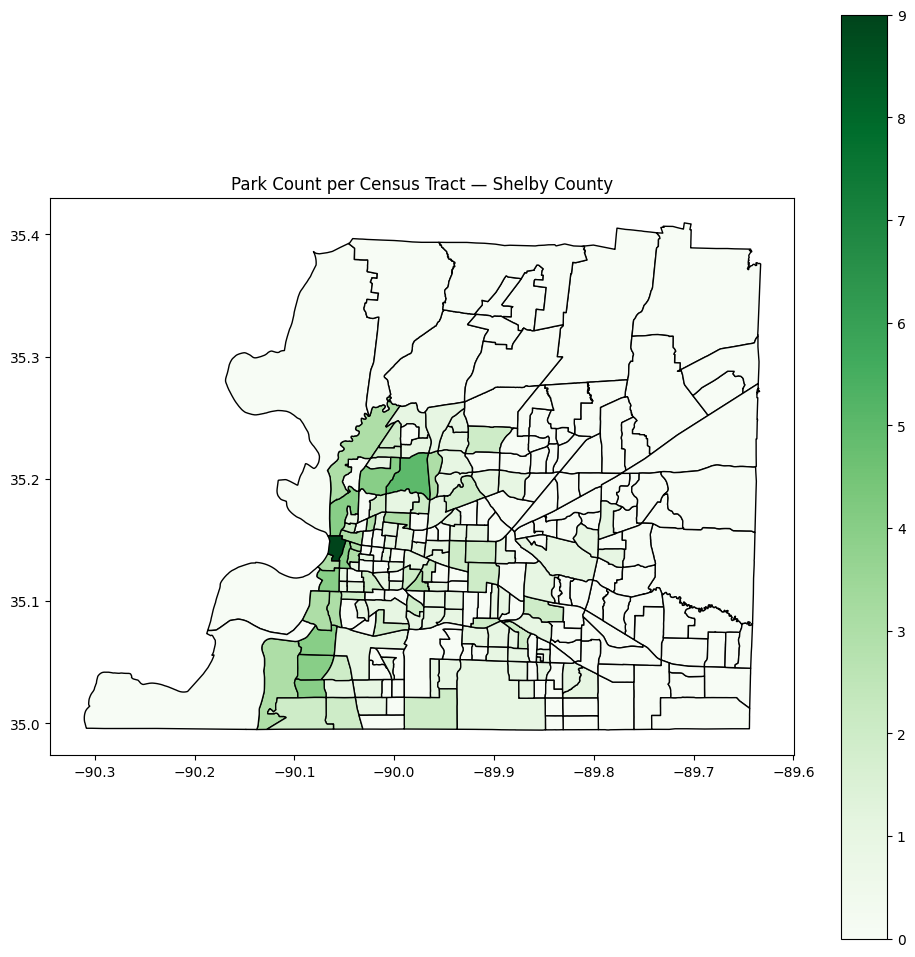

In [29]:
shelby_tracts.plot(
    column='park_count',
    cmap='Greens',
    legend=True,
    figsize=(12,12),
    edgecolor='black'
)
plt.title('Park Count per Census Tract — Shelby County')
plt.show()


In [39]:
m = folium.Map(location=[35.15, -90.05], zoom_start=10, tiles='Esri WorldImagery')
# Add parks
for _, row in parks.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4,
        color='blue',
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

m

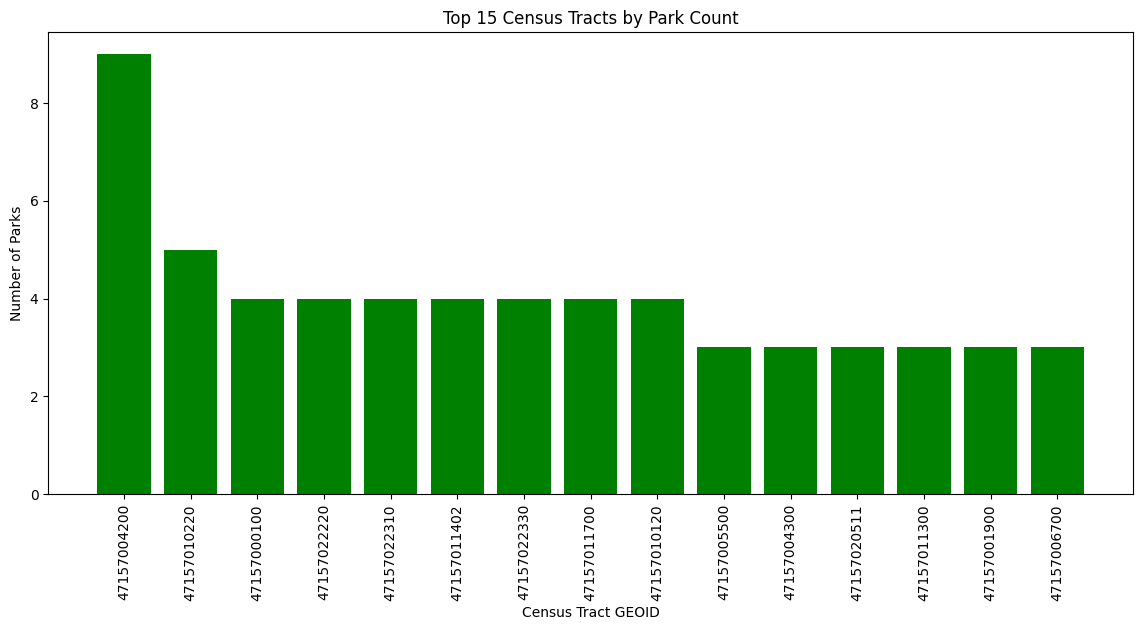

In [40]:
top15 = shelby_tracts.sort_values('park_count', ascending=False).head(15)

plt.figure(figsize=(14,6))
plt.bar(top15['GEOID'], top15['park_count'], color='green')
plt.xticks(rotation=90)
plt.title('Top 15 Census Tracts by Park Count')
plt.xlabel('Census Tract GEOID')
plt.ylabel('Number of Parks')
plt.show()


# **Spatial Story: Access to Parks in Shelby County**

Public parks are more than patches of green space, they’re vital infrastructure for health, recreation, and community connection. In Memphis, where urban density and socioeconomic disparities shape daily life, the distribution of parks reveals how geography can either support or limit access to nature. Using the 2025 TIGER/Line Census Tracts and the City of Memphis Parks dataset, this analysis explores how park availability varies across Shelby County and what those patterns suggest about equity in public amenities.

The census tract map provides the foundation for understanding neighborhood boundaries. When the park locations are overlaid, clear spatial contrasts emerge. Central Memphis and the eastern suburbs show dense clusters of parks, while tracts in the southwest and north appear noticeably sparse. The spatial join quantifies this pattern: some tracts contain more than a dozen parks, while others have none. This uneven distribution raises questions about how historical development, zoning, and investment priorities have shaped access to green space.

A choropleth map of park counts per tract highlights these disparities visually. Tracts with higher park density form a corridor stretching eastward from Midtown toward Germantown, areas historically associated with higher income and newer residential development. In contrast, tracts near the industrial riverfront and older neighborhoods show fewer parks. The interactive map reinforces this divide, allowing viewers to zoom into specific communities and see how park locations align with population centers. The bar chart of top tracts by park count further emphasizes concentration: a handful of tracts dominate the list, suggesting that park resources are not evenly distributed county‑wide.

These findings echo broader themes in urban geography. Access to parks often correlates with socioeconomic status, transportation infrastructure, and local policy decisions. Neighborhoods with limited green space may face higher heat exposure, fewer recreational opportunities, and reduced community cohesion. Recognizing these spatial inequalities is the first step toward addressing them. City planners and community advocates can use this data to identify underserved areas and prioritize new park development or maintenance funding.

In conclusion, mapping parks across Shelby County transforms abstract data into a tangible story about place and equity. The analysis shows that while Memphis offers many parks overall, their distribution reflects the city’s uneven landscape of privilege and opportunity. By visualizing these patterns, we gain not only geographic insight but also a clearer sense of how public space can shape the quality of life for every resident.